# Задача 4.7 — Иван и Пётр, ожидание 15 минут

---

## 1. Условие

Иван и Пётр договорились о встрече между 11 и 12 часами. Каждый приходит и ждёт другого не более 15 минут. Найдите вероятности событий:

- $A$ — встреча состоялась;
- $B$ — встреча не состоялась;
- $C$ — Ивану не пришлось ждать Петра;
- $D$ — встреча состоялась после 11:30;
- $E$ — Иван опоздал на встречу;
- $F$ — встреча состоялась, когда до истечения часа оставалось меньше 5 минут.

Постройте график $p^{\wedge}(A)$ от $N = 150\,000$.

---

## 2. Теоретическая часть

Пусть $x, y \in [0, 60]$ — минуты прихода Ивана и Петра. Равномерное распределение в квадрате $60\times 60$.

- $A$: $|x - y| \le 15$. Площадь: $60^2 - 2\cdot\dfrac{45^2}{2} = 3600 - 2025 = 1575$, $P(A) = \dfrac{1575}{3600} = \dfrac{7}{16}$.
- $B = \bar A$: $P(B) = \dfrac{9}{16}$.
- $C$: Иван пришёл не позже Петра, $x \le y$: $P(C) = \dfrac12$.
- $D$: $\max(x, y) \ge 30$ **и** $|x - y| \le 15$. Считаем площадь.
- $E$: $x > y$ (Иван опоздал) — $P(E) = \dfrac12$.
- $F$: $|x - y| \le 15$ и $\max(x, y) > 55$ (до конца часа меньше 5 минут), т.е. встреча происходит в последние 5 минут.

Точные значения для $D$ и $F$ удобно получить численно/геометрически.

---

## 3. Решение

P(A) ≈ 0.436307  (теор. 7/16 = 0.437500)
P(B) ≈ 0.563693  (теор. 9/16 = 0.562500)
P(C) ≈ 0.501193  (теор. 0.5)
P(D) ≈ 0.248613
P(E) ≈ 0.498807  (теор. 0.5)
P(F) ≈ 0.041500


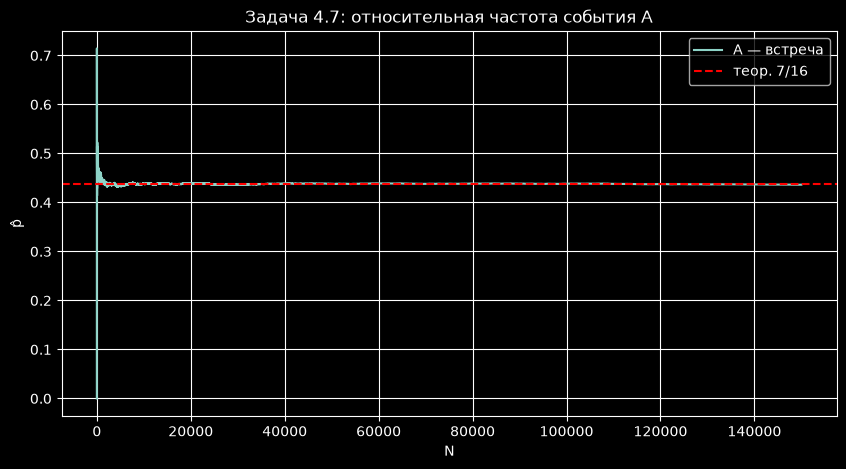

In [1]:
import numpy as np
import matplotlib.pyplot as plt

w = 15
N = 150_000
rng = np.random.default_rng(seed=6)
x = rng.uniform(0, 60, N)   # Иван
y = rng.uniform(0, 60, N)   # Пётр

meet = np.abs(x - y) <= w
A = meet
B = ~meet
C = x <= y
D = meet & (np.maximum(x, y) >= 30)
E = x > y
F = meet & (np.maximum(x, y) > 55)

def freq(mask):
    return np.cumsum(mask) / np.arange(1, N+1)

print(f"P(A) ≈ {A.mean():.6f}  (теор. 7/16 = {7/16:.6f})")
print(f"P(B) ≈ {B.mean():.6f}  (теор. 9/16 = {9/16:.6f})")
print(f"P(C) ≈ {C.mean():.6f}  (теор. 0.5)")
print(f"P(D) ≈ {D.mean():.6f}")
print(f"P(E) ≈ {E.mean():.6f}  (теор. 0.5)")
print(f"P(F) ≈ {F.mean():.6f}")

plt.figure(figsize=(10, 5))
plt.plot(freq(A), label="A — встреча")
plt.axhline(7/16, color="r", ls="--", label="теор. 7/16")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Задача 4.7: относительная частота события A")
plt.show()